# Braun et al. (2026), Supp. Fig. 2 — the common profile survives sparse connectivity (WP0.4)

> A: test correlation against the fraction of (left) randomly chosen presynaptic neurons whose outgoing weights are
> zero and untrained, (middle) consecutive presynaptic neurons in the sequence ordering, (right) randomly chosen
> synapses. Up to 95% / 35% / 95% can be removed. B: correlation between each sparse network's profile and the dense
> mean profile. C–F: example matrices and profiles: dense; 25% random presynaptic (profile corr 0.930 ± 0.004); last
> 25% in the ordering (0.910 ± 0.005); 85% random synapses (0.940 ± 0.003).

**Settings.** Masks (a) and (b) at dev settings; mask (c) (one P_i per row, Methods eq. 18–19) at reduced settings
(5 realisations × (60 + 10) iterations), because its cost scales as N·L² per update. Mask (c) covers fractions
0.75–0.95, where the paper's claim lies. The dense reference profile is the mean profile of the Fig. 1 run (final
settings). Sparse runs share the Fig. 1 target (a = 0.5, σ = 1.7 s, b = 0).

**Panels:** A performance · B profile correlation with the dense profile · C–F examples.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet import conventions as cv
from seqnet.training.rls import pearson

style()
fig = Figure("wp0", "braun_supp2")
cfg = fig.config()
dense = wp0.get(0.5, 1.7, 0.0, cfg["reference"], store_full="all")
ref = cv.profile_from_matrix(dense.summary["mean_W"])
def nod0(p):  # exclude the self-connection, which dominates the profile scale
    return np.delete(p, 0, axis=-1)

## Panels A–B — performance and profile similarity against the sparsity fraction

In [2]:
out = {}
for kind, (st, fr) in wp0.SPARSITY.items():
    tc, pc_mean, pc_sd = [], [], []
    for f in fr:
        r = wp0.get_sparse(kind, f)
        n_te = r.meta["config"]["n_test"]
        tc.append(r.summary["corr"][:, -n_te:].mean(1))
        pc = np.array([pearson(nod0(p), nod0(ref)) for p in r.summary["profiles"]])
        pc_mean.append(pc.mean()); pc_sd.append(pc.std())
    out[f"{kind}_frac"] = np.array(fr); out[f"{kind}_test_mean"] = np.array([t.mean() for t in tc]); out[f"{kind}_test_sd"] = np.array([t.std() for t in tc])
    out[f"{kind}_pc_mean"] = np.array(pc_mean); out[f"{kind}_pc_sd"] = np.array(pc_sd)
fig.save("AB_sweeps", **out)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp2/AB_sweeps.npz')

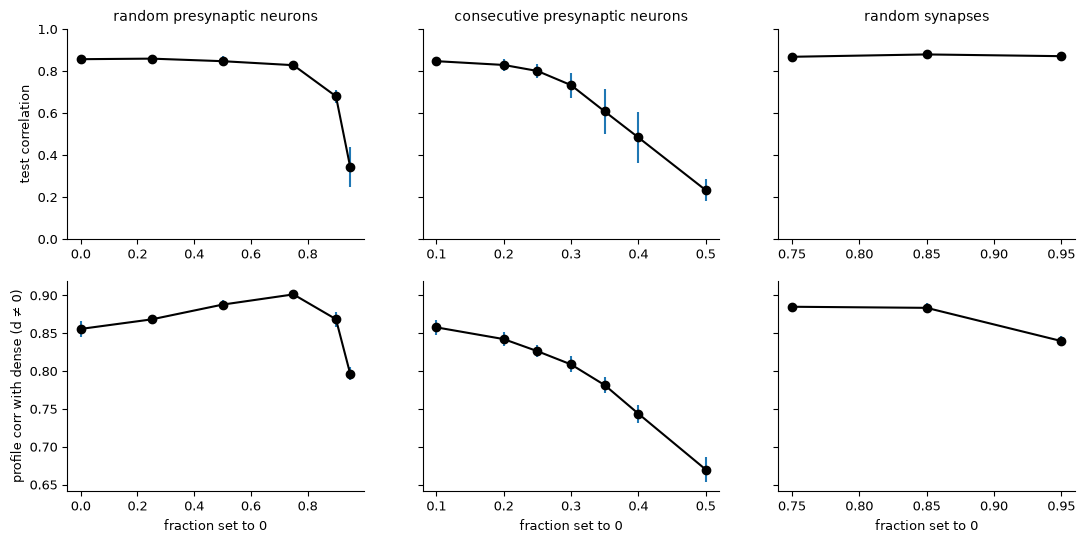

In [3]:
d = fig.load("AB_sweeps")
kinds = list(wp0.SPARSITY); titles = ["random presynaptic neurons", "consecutive presynaptic neurons", "random synapses"]
F, axs = plt.subplots(2, 3, figsize=(13, 6), sharey="row")
for j, (k, t) in enumerate(zip(kinds, titles)):
    axs[0, j].errorbar(d[f"{k}_frac"], d[f"{k}_test_mean"], yerr=d[f"{k}_test_sd"], fmt="ko-", ecolor="tab:blue"); axs[0, j].set_title(t)
    axs[1, j].errorbar(d[f"{k}_frac"], d[f"{k}_pc_mean"], yerr=d[f"{k}_pc_sd"], fmt="ko-", ecolor="tab:blue"); axs[1, j].set_xlabel("fraction set to 0")
axs[0, 0].set_ylabel("test correlation"); axs[1, 0].set_ylabel("profile corr with dense (d ≠ 0)"); axs[0, 0].set_ylim(0, 1)
fig.savefig("AB_sweeps", F); plt.show()

## Panels C–F — example matrices (realisation 1) and mean profiles

In [4]:
ex = {}
for pan, (kind, f) in cfg["examples"].items():
    r = dense if f == 0.0 else wp0.get_sparse(kind, f)
    W = r.W(0); d_, cp = cv.centred_profile(cv.profile_from_matrix(r.summary["mean_W"]))
    pcs = np.array([pearson(nod0(p), nod0(ref)) for p in r.summary["profiles"]])
    ex.update({f"{pan}_W": W.astype(np.float32), f"{pan}_cp": cp, f"{pan}_pc_mean": pcs.mean(), f"{pan}_pc_sd": pcs.std()})
fig.save("CDEF_examples", d=d_, **ex)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp2/CDEF_examples.npz')

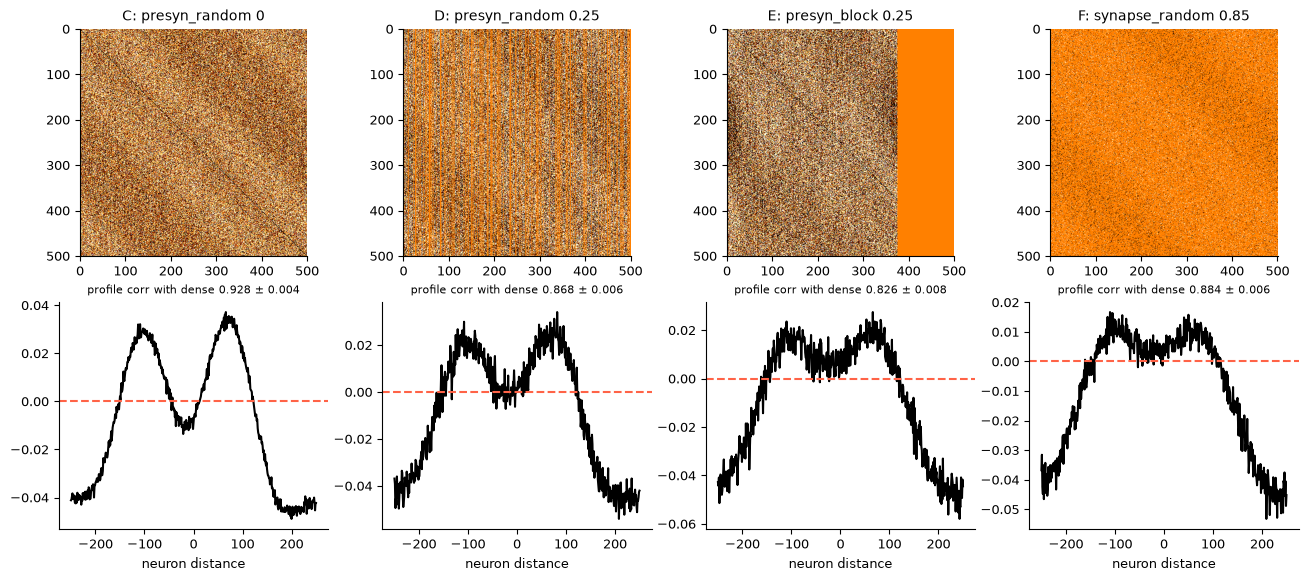

In [5]:
d = fig.load("CDEF_examples")
F, axs = plt.subplots(2, 4, figsize=(16, 6.5))
for j, (pan, (kind, f)) in enumerate(cfg["examples"].items()):
    axs[0, j].imshow(d[f"{pan}_W"], cmap="afmhot", vmin=-0.3, vmax=0.3); axs[0, j].set_title(f"{pan}: {kind} {f:g}")
    cp = d[f"{pan}_cp"].copy(); i0 = int(np.nonzero(d["d"] == 0)[0][0]); cp[i0] = 0.5 * (cp[i0 - 1] + cp[i0 + 1])
    axs[1, j].plot(d["d"], cp, "k"); axs[1, j].axhline(0, color="tomato", ls="--"); axs[1, j].set_xlabel("neuron distance")
    axs[1, j].set_title(f"profile corr with dense {float(d[f'{pan}_pc_mean']):.3f} ± {float(d[f'{pan}_pc_sd']):.3f}", fontsize=8)
fig.savefig("CDEF_examples", F); plt.show()

## Acceptance

In [6]:
a = fig.load("AB_sweeps"); e = fig.load("CDEF_examples")
def ok_up_to(k, thr=0.7):
    good = a[f"{k}_test_mean"] >= thr
    return float(a[f"{k}_frac"][good].max()) if good.any() else 0.0
fig.checks([
    {"item": "(a) random presynaptic: performance kept up to 0.9", "criterion": "test corr >= 0.7 up to fraction >= 0.9", "value": ok_up_to("presyn_random"), "passed": ok_up_to("presyn_random") >= 0.9},
    {"item": "(b) consecutive block fails beyond ~0.35", "criterion": "largest fraction with test corr >= 0.7 within [0.2, 0.5]", "value": ok_up_to("presyn_block"), "passed": 0.2 <= ok_up_to("presyn_block") <= 0.5},
    {"item": "(c) random synapses: performance kept up to 0.9", "criterion": "test corr >= 0.7 up to fraction >= 0.9 (quick settings)", "value": ok_up_to("synapse_random"), "passed": ok_up_to("synapse_random") >= 0.9},
    {"item": "profile corr with dense, examples D/E/F", "criterion": "within 0.1 of the paper (0.930 / 0.910 / 0.940)",
     "value": [float(e["D_pc_mean"]), float(e["E_pc_mean"]), float(e["F_pc_mean"])],
     "passed": bool(abs(e["D_pc_mean"] - 0.93) < 0.1 and abs(e["E_pc_mean"] - 0.91) < 0.1 and abs(e["F_pc_mean"] - 0.94) < 0.1)},
])

[FAIL] (a) random presynaptic: performance kept up to 0.9: 0.75
[PASS] (b) consecutive block fails beyond ~0.35: 0.3
[PASS] (c) random synapses: performance kept up to 0.9: 0.95
[PASS] profile corr with dense, examples D/E/F: [0.8684186620685193, 0.8264289915185644, 0.8836590040171355]


WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_supp2/acceptance.json')